# Heston Option Pricing and Calibration

**Anna Docheva and Julien Kanaan**

Course project in deep learning in finance at École Polytechnique.

# 0. Setup

In [17]:
# --- Imports & global settings ---
import os, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import norm
from scipy.optimize import minimize
from time import perf_counter
import datetime
import joblib
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
# Training with early stopping on validation RMSE
os.makedirs("Data", exist_ok=True)
file_save_best_model = "Data/best_mlp.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED=0
np.random.seed(SEED)
torch.manual_seed(SEED)

# 1 The Heston stochastic volatility model


The Heston Model (Heston, 1993) under the risk-neutral measure $\mathbb{Q}$:

\begin{equation}
  \begin{aligned}
    \frac{dS_t}{S_t} &= r\, dt + \sqrt{v_t}\, dW_t,\\
    dv_t &= \alpha(\beta - v_t)\, dt + \delta \sqrt{v_t}\, dB_t,\\
    d\langle W,B\rangle_t &= \rho\, dt.
  \end{aligned}
\end{equation}

We calibrate the parameter vector $\Theta=(v_0,\alpha,\beta,\delta,\rho)$.

The Heston model is well adapted to fit the volatiliy smile: Heston model's parameters can adapt lots of smile shapes.






We consider **European call options** with payoff $(S_T-K)^+$.  
In this project, calibration is performed **on call prices** (as in your Chapter 3 tutorials), not on implied volatilities.

You will use a neural network surrogate fast pricer:
$$
(\Theta, K) \mapsto C_{\text{Heston}}(K,T)
$$
for a **single maturity** $T$ (same setting as your market dataset).


# Your task

Inspired by your Chapter 3 notebooks (FastPricing_BS_Surrogate and Calibration_NN):

1) Generate simulations of the Heston model
2) Implement the Heston pricer (via Monte Carlo) to generate synthetic training data
3) Train a deep fast pricer on the synthetic data and check performance
4) Train a deep fast pricer
5) Analyze the results and find out what was wrong in the procedure

# 2 Monte Carlo simulation under the Heston model

In this project, we simulate asset price trajectories under the Heston stochastic volatility model
in order to compute option prices via Monte Carlo.


## 2.2 Time discretization

We discretize time:

$$
t_n = n \Delta t, \quad \Delta t = \frac{T}{N}.
$$

We consider correlated Brownian increments:

$$
\begin{aligned}
\Delta W_n &= \sqrt{\Delta t}\, Z_1^n, \\
\Delta B_n &= \sqrt{\Delta t}\left( \rho Z_1^n + \sqrt{1-\rho^2} Z_2^n \right).
\end{aligned}
$$

with $ Z_1^n, Z_2^n \sim \mathcal{N}(0,1) $


---

## 2.3 Variance discretization

A simple Euler scheme gives:

$$
v_{n+1} = v_n + \alpha(\beta - v_n)\Delta t
          + \delta \sqrt{v_n}\, \Delta B_n.
$$

However, this may produce negative values. A common practical fix is the **Full Truncation Euler scheme**:

$$
v_{n+1} = v_n + \alpha(\beta - v_n^+)\Delta t
          + \delta \sqrt{v_n^+}\, \Delta B_n,
$$

with $v_n^+ = \max(v_n, 0).$


---

## 2.4 Stock price discretization

Using a log-Euler scheme:

$$
S_{n+1} =
S_n \exp\left(
(r - \tfrac{1}{2} v_n^+)\Delta t
+ \sqrt{v_n^+}\, \Delta W_n
\right).
$$


<span style="color: blue;">**2.1** Implement a function that generates trajectories from the Heston model.</span>


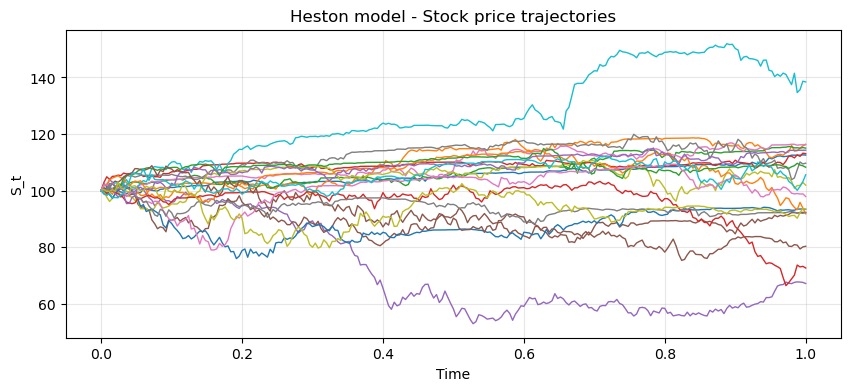

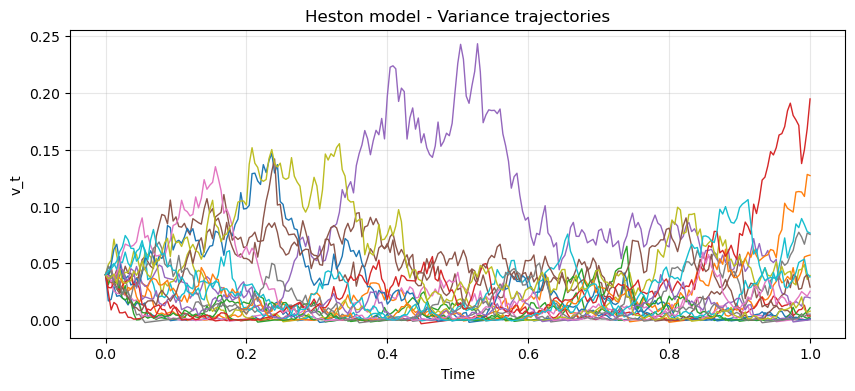

In [18]:
def simulate_heston(S0,v0,r,alpha,beta,delta,rho,T,n_steps,n_paths):
    """
    Simulate trajectories under the Heston model:
        dS_t / S_t = r dt + sqrt(v_t) dW_t
        dv_t = alpha (beta - v_t) dt + delta sqrt(v_t) dB_t
        d<W,B>_t = rho dt
    using Full Truncation Euler scheme.

    Outputs
    -------
    S : array (n_paths, n_steps+1)
    v : array (n_paths, n_steps+1)
    """

    dt = T / n_steps

    S_paths = np.zeros((n_paths, n_steps + 1))
    v_paths = np.zeros((n_paths, n_steps + 1))

    S_paths[:, 0] = S0
    v_paths[:, 0] = v0

    for t in range(n_steps):
        # Generate correlated Brownian increments
        Z1 = np.random.normal(0.0, 1.0, size=n_paths)
        Z2 = np.random.normal(0.0, 1.0, size=n_paths)
        dW = np.sqrt(dt) * Z1
        dB = np.sqrt(dt) * (rho * Z1 + np.sqrt(1.0 - rho**2) * Z2)

        # Full truncation Euler scheme:
        v_prev = v_paths[:, t]
        v_pos = np.maximum(v_prev, 0.0)

        v_next = v_prev + alpha * (beta - v_pos) * dt + delta * np.sqrt(v_pos) * dB

        S_prev = S_paths[:, t]
        S_next = S_prev * np.exp((r - 0.5 * v_pos) * dt + np.sqrt(v_pos) * dW)
        
        S_paths[:, t + 1] = S_next
        v_paths[:, t + 1] = v_next

    return S_paths, v_paths



# Parameters
S0 = 100
v0 = 0.04
r = 0.02
alpha = 2.0
beta = 0.04
delta = 0.6
rho = -0.7
T = 1.0

n_steps = 250
n_paths = 20

# Simulate
S_paths, v_paths = simulate_heston(
    S0, v0, r,
    alpha, beta, delta, rho,
    T, n_steps, n_paths,
)

# Time grid
t_grid = np.linspace(0, T, n_steps + 1)

# Plot stock paths
plt.figure(figsize=(10,4))
for i in range(n_paths):
    plt.plot(t_grid, S_paths[i], lw=1)
plt.title("Heston model - Stock price trajectories")
plt.xlabel("Time")
plt.ylabel("S_t")
plt.grid(alpha=0.3)
plt.show()

# Plot variance paths
plt.figure(figsize=(10,4))
for i in range(n_paths):
    plt.plot(t_grid, v_paths[i], lw=1)
plt.title("Heston model - Variance trajectories")
plt.xlabel("Time")
plt.ylabel("v_t")
plt.grid(alpha=0.3)
plt.show()


# 3. Call option price and dataset generation

Now it is possible to approximate call option prices by Monte Carlo

<span style="color: blue;">**3.1** Implement a function that generates trajectories from the Heston model.</span>

In [19]:
def heston_call_price_mc(S0, v0, r, alpha, beta, delta, rho,T, K,n_steps,n_paths):
    S_paths, _ = simulate_heston(
        S0, v0, r, alpha, beta, delta, rho, T, n_steps, n_paths
    )
    payoff = np.maximum(S_paths[:, -1] - K, 0.0)
    price = np.exp(-r * T) * np.mean(payoff)
    return price


## 3.1 Dataset generation

The objective is to randomly sample Heston parameters in the training domain 
$\mathcal{D}_{\text{domain}}$:

- $v_0 \in [0.01, 0.12]$
- $\alpha \in [0.3, 4.0]$
- $\beta \in [0.01, 0.12]$
- $\delta \in [0.1, 1.2]$
- $\rho \in [-0.95, -0.05]$
- $S_0 = 274.73$
- $K \in [60, 140]$
- $T  = 0.2$


For each $x \in \mathcal{D}_{\text{domain}}$, we then compute Monte Carlo prices $y$ 
using the Heston simulation scheme implemented previously.

The surrogate model will therefore learn the mapping:

$$
(v_0, \alpha, \beta, \delta, \rho, S_0, K, T)
\;\longmapsto\;
C_{\text{Heston}}(S_0,K,T).
$$

<span style="color: blue;"> **3.1** Implement a function `build_dataset(n_samples, n_simulations)` that builds a dataset $(x_i, y_i) \in \mathcal{D}_{\text{domain}}$, for $i = 1, \dots, n_{\text{samples}}$</span>

<span style="color: blue;">**3.2** Use this function to generate a dataset of 10,000 samples, and split the dataset into $X_{\text{train}}, y_{\text{train}}, X_{\text{val}}, y_{\text{val}}, X_{\text{test}}, y_{\text{test}}$  with a respective repartition (50%, 10%, 40%).</span>

In [20]:
# ------------------------------------------
# Dataset builder
# ------------------------------------------

def sample_domain_heston(n_samples):
    """
    Sample parameters in the Heston training domain:
    (v0, alpha, beta, delta, rho, S0, K, T).
    """
    v0 = np.random.uniform(0.01, 0.12, size=n_samples)
    alpha = np.random.uniform(0.3, 4.0, size=n_samples)
    beta = np.random.uniform(0.01, 0.12, size=n_samples)
    delta = np.random.uniform(0.1, 1.2, size=n_samples)
    rho = np.random.uniform(-0.95, -0.05, size=n_samples)
    S0 = np.full(n_samples, 274.73)
    K = np.random.uniform(60.0, 140.0, size=n_samples)
    T = np.full(n_samples, 0.2)
    return np.stack([v0, alpha, beta, delta, rho, S0, K, T], axis=1)

def build_dataset(n_samples, n_paths, n_steps=100):
    """
    Build (X, y) with Monte Carlo Heston call prices.
    X columns: (v0, alpha, beta, delta, rho, S0, K, T)
    y: call prices.
    """
    X = sample_domain_heston(n_samples)
    y = np.empty((n_samples,), dtype=np.float32)
    r = 0.01
    t0 = perf_counter()

    for i in range(n_samples):
        v0, alpha, beta, delta, rho, S0, K, T = X[i]
        y[i] = heston_call_price_mc(
            S0=S0,
            v0=v0,
            r=r,
            alpha=alpha,
            beta=beta,
            delta=delta,
            rho=rho,
            T=T,
            K=K,
            n_steps=n_steps,
            n_paths=n_paths,
        )
        if (i + 1) % max(1, n_samples // 10) == 0:
            print(f"{i+1}/{n_samples} done")

    t1 = perf_counter()
    print(f"Dataset generated in {t1-t0:.2f}s (n_samples={n_samples}, n_paths={n_paths})")
    return X, y.reshape(-1, 1)

# Generate dataset
X, y = build_dataset(n_samples=10000,n_paths=5000,n_steps=50)

# ------------------------------------------
# Train / Val / Test split
# ------------------------------------------

def random_split(X, y, train_ratio=0.5, val_ratio=0.1):
    n = X.shape[0]
    if y.shape[0] != n:
        raise ValueError(f"X and y must have the same number of samples (X:{n}, y:{y.shape[0]})")

    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)

    idx = np.random.permutation(n)
    idx_train = idx[:n_train]
    idx_val = idx[n_train:n_train + n_val]
    idx_test = idx[n_train + n_val:]

    X_train, y_train = X[idx_train], y[idx_train]
    X_val, y_val = X[idx_val], y[idx_val]
    X_test, y_test = X[idx_test], y[idx_test]

    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

(X_train, y_train), (X_val, y_val), (X_test, y_test) = random_split(X, y)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

1000/10000 done
2000/10000 done
3000/10000 done
4000/10000 done
5000/10000 done
6000/10000 done
7000/10000 done
8000/10000 done
9000/10000 done
10000/10000 done
Dataset generated in 92.91s (n_samples=10000, n_paths=5000)
Train: (5000, 8)
Val  : (1000, 8)
Test : (4000, 8)


## 3.2 Data normalization

<span style="color: blue;"> **3.3** Standardize all the data in an appropriate way</span>


In [21]:
from sklearn.preprocessing import StandardScaler

scaler_X = StandardScaler().fit(X_train)
X_train_s = scaler_X.transform(X_train)
X_val_s = scaler_X.transform(X_val)
X_test_s = scaler_X.transform(X_test)

scaler_y = StandardScaler().fit(y_train)
y_train_s = scaler_y.transform(y_train)
y_val_s = scaler_y.transform(y_val)
y_test_s = scaler_y.transform(y_test)

# Transform Dataset in Torch objects
train_ds = TensorDataset(
    torch.tensor(X_train_s, dtype=torch.float32),
    torch.tensor(y_train_s, dtype=torch.float32),
)
val_ds = TensorDataset(
    torch.tensor(X_val_s, dtype=torch.float32),
    torch.tensor(y_val_s, dtype=torch.float32),
)
test_ds = TensorDataset(
    torch.tensor(X_test_s, dtype=torch.float32),
    torch.tensor(y_test_s, dtype=torch.float32),
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=False)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# Sanity check
print("X_train mean (approx):", X_train_s.mean(axis=0))
print("X_train std  (approx):", X_train_s.std(axis=0))

# Saving scaling parameters
joblib.dump(scaler_X, "scaler_X.joblib")
joblib.dump(scaler_y, "scaler_y.joblib")



X_train mean (approx): [ 6.82232049e-16  4.22712976e-15  5.21760413e-15  1.16009868e-14
  3.85258830e-15  1.42108547e-11 -2.49592569e-15 -1.80688797e-14]
X_train std  (approx): [1. 1. 1. 1. 1. 0. 1. 0.]


['scaler_y.joblib']

## 4. Surrogate model: a simple MLP

Now that all is ready to train a Neural Network, we consider a simple MLP surrogate model.

We propose a fully-connected network:
- **input dim:** 5 (features $(v_0, \alpha, \beta, \delta, \rho, S_0, K, T)$ standardized)
- **Hidden layers:** 3 layers with sizes 128 --> 128 --> 64, all with ReLU
- **Output dim:** 1 (scaled (standardized) price)
- **Loss function:** MSE (nn.MSELoss)
- **Optimizer:** Adam (Learning rate 1e$^{-3}$

<span style="color: blue;">**4.1** Build the class MLP with the above characteristics  </span>

<span style="color: blue;">**4.2** Implement the function `run_epoch(loader, train)` that runs one epoch</span>
- <span style="color: blue;">sets model.train() if train=True otherwise model.eval()</span>
- <span style="color: blue;">iterates over the loader, sends</span>
- <span style="color: blue;">returns the losses </span>

<span style="color: blue;">**4.3** Implement the training procedure on 250 Epochs, with an overfitting control  </span>
- <span style="color: blue;">with a patience counter of 20 (if no loss decrease during 20 Epochs, then stop</span>
- <span style="color: blue;">save the best model in `Data/best_mlp.pt`</span>

<span style="color: blue;">**4.4** Plot the MSE losses (Learning Curves) for the train and val sets  </span>

Epoch 010 | Train MSE=0.000750 | Val MSE=0.000771
Epoch 020 | Train MSE=0.000698 | Val MSE=0.000702
Epoch 030 | Train MSE=0.000921 | Val MSE=0.002107
Early stopping at 35
Best validation MSE: 0.000683


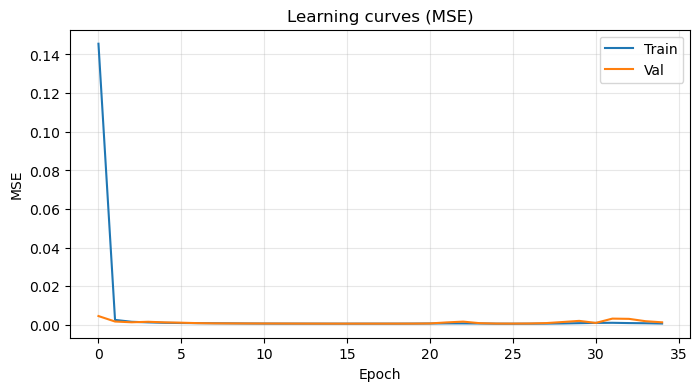

In [22]:
# 4.1 Model definition (MLP surrogate)
EPOCHS = 250
patience = 20
best_val = math.inf
patience_cnt = 0

# Save best model 
file_save_best_model = "Data/best_mlp.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MLP(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x)


model = MLP(in_dim=X_train_s.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


# 4.2 run_epoch function
def run_epoch(loader, train=False):
    if train:
        model.train()
    else:
        model.eval()

    losses = []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        if train:
            pred = model(xb)
            loss = criterion(pred, yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                pred = model(xb)
                loss = criterion(pred, yb)

        losses.append(loss.item())

    return np.mean(losses)

# 4.3 Training loop with early stopping
train_data = []
val_data = []

for epoch in range(1, EPOCHS + 1):
    train_mse = run_epoch(train_loader, train=True)
    val_mse = run_epoch(val_loader, train=False)

    train_data.append(train_mse)
    val_data.append(val_mse)

    if val_mse < best_val - 1e-6:
        best_val = val_mse
        patience_cnt = 0
        torch.save(model.state_dict(), file_save_best_model)
    else:
        patience_cnt += 1

    if epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | Train MSE={train_mse:.6f} | Val MSE={val_mse:.6f}")

    if patience_cnt >= patience:
        print(f"Early stopping at {epoch}")
        break

print(f"Best validation MSE: {best_val:.6f}")


# 4.4 Learning curves (Train / Val MSE)
plt.figure(figsize=(8, 4))
plt.plot(train_data, label="Train")
plt.plot(val_data, label="Val")
plt.title("Learning curves (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()



## 5. Evaluation (accuracy)

Now the surrogate model is trained, let's evaluate its performance on the test set

<span style="color: blue;">**5.1** Load the best model saved in `file_save_best_model` and the scaling parameters with command `joblib.load` and evaluate with `model.eval()`</span>

<span style="color: blue;">**5.2** Compute the predicted `y_test_pred` from X_test (test_loader tensor) and unscale to get `y_test_hat`</span>

<span style="color: blue;">**5.3** Compute the MAE and RMSE, and give the scatter plot MC price vs. NN price </span>

<span style="color: blue;">**5.4** Give the scatter plot BS price vs. NN price </span>

Test MAE : 0.482019
Test RMSE: 0.607386


<local path>:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(file_save_best_model, map_location=device))


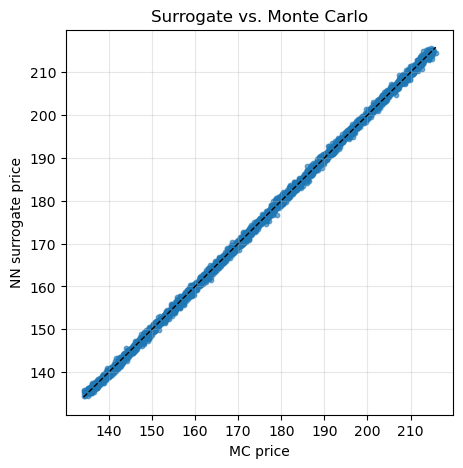

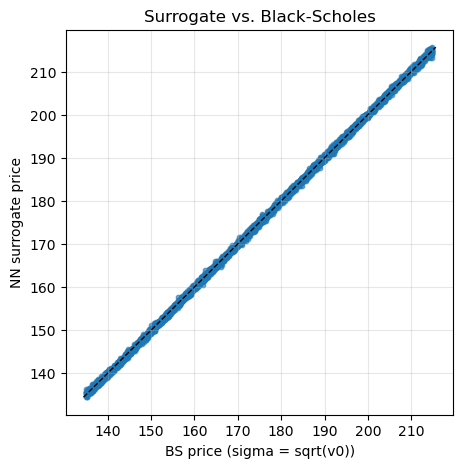

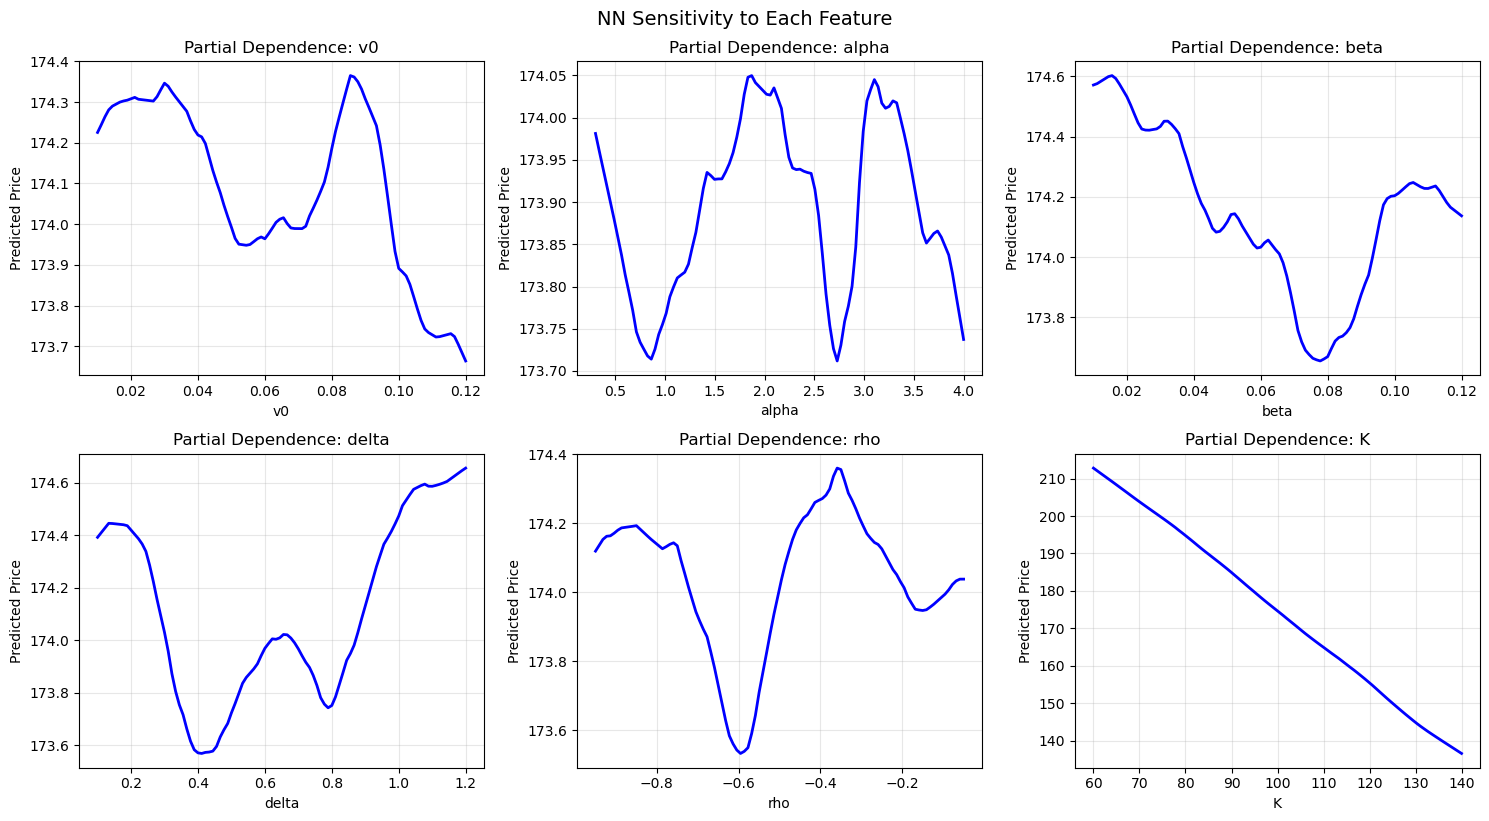

In [23]:
# 5.1 Load best model  and scaling parameters
model.load_state_dict(torch.load(file_save_best_model, map_location=device))
model.eval()

scaler_X = joblib.load("scaler_X.joblib")
scaler_y = joblib.load("scaler_y.joblib")

# 5.2 Predict on test set and unscale outputs
with torch.no_grad():
    y_test_pred = []
    for xb, _ in test_loader:
        xb = xb.to(device)
        y_test_pred.append(model(xb).cpu().numpy())
    y_test_pred = np.concatenate(y_test_pred, axis=0)

y_test_hat = scaler_y.inverse_transform(y_test_pred)

# 5.3 MAE, RMSE and scatter MC vs NN
mae = float(np.mean(np.abs(y_test - y_test_hat)))
rmse = float(np.sqrt(np.mean((y_test - y_test_hat) ** 2)))
print(f"Test MAE : {mae:.6f}")
print(f"Test RMSE: {rmse:.6f}")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_test_hat, s=10, alpha=0.6)
m = float(min(y_test.min(), y_test_hat.min()))
M = float(max(y_test.max(), y_test_hat.max()))
plt.plot([m, M], [m, M], "k--", lw=1)
plt.xlabel("MC price")
plt.ylabel("NN surrogate price")
plt.title("Surrogate vs. Monte Carlo")
plt.grid(alpha=0.3)
plt.show()


# 5.4 Scatter BS vs NN
# we use sigma = sqrt(v0) as a proxy to build a BS reference curve

def bs_call_price(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


# X_test columns: (v0, alpha, beta, delta, rho, S0, K, T)
v0 = X_test[:, 0]
S0 = X_test[:, 5]
K = X_test[:, 6]
Tmt = X_test[:, 7]
r = 0.01

sigma_proxy = np.sqrt(np.maximum(v0, 1e-12))
y_bs = bs_call_price(S0, K, Tmt, r, sigma_proxy).reshape(-1, 1)

plt.figure(figsize=(5, 5))
plt.scatter(y_bs, y_test_hat, s=10, alpha=0.6)
m = float(min(y_bs.min(), y_test_hat.min()))
M = float(max(y_bs.max(), y_test_hat.max()))
plt.plot([m, M], [m, M], "k--", lw=1)
plt.xlabel("BS price (sigma = sqrt(v0))")
plt.ylabel("NN surrogate price")
plt.title("Surrogate vs. Black-Scholes")
plt.grid(alpha=0.3)
plt.show()

# PARTIAL DEPENDENCE ANALYSIS

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
feature_names_pd = ['v0', 'alpha', 'beta', 'delta', 'rho', 'K']
feature_indices_pd = [0, 1, 2, 3, 4, 6]
X_median = np.median(X_train, axis=0)

for idx, (feat_idx, feat_name) in enumerate(zip(feature_indices_pd, feature_names_pd)):
    ax = axes.flatten()[idx]
    lo, hi = X_train[:, feat_idx].min(), X_train[:, feat_idx].max()
    grid = np.linspace(lo, hi, 100)
    X_grid = np.tile(X_median, (100, 1))
    X_grid[:, feat_idx] = grid
    X_grid_sc = scaler_X.transform(X_grid)
    X_grid_t = torch.tensor(X_grid_sc, dtype=torch.float32).to(device)
    with torch.no_grad():
        pred_sc = model(X_grid_t).cpu().numpy()
    pred = scaler_y.inverse_transform(pred_sc)
    ax.plot(grid, pred.flatten(), 'b-', lw=2)
    ax.set_xlabel(feat_name)
    ax.set_ylabel('Predicted Price')
    ax.set_title(f'Partial Dependence: {feat_name}')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('NN Sensitivity to Each Feature', fontsize=14, y=1.02)
plt.show()


# 6 Calibration on real data

The objective is to calibrate the Black-Scholes model, i.e. to estimated the implied volatility $\sigma_\text{imp}$.

We propose to estimate $\theta = (v_0, \alpha, \beta, \delta, \rho)$ by minimizing the quadrati error:
\begin{equation}
\sigma_\text{imp} = \arg\min_{\theta} J^{method}(\theta) 
\end{equation}
with 
\begin{equation}
J^{method}(\theta)  = \frac{1}{I}\sum_{i=1}^I \| C^{mkt}_i - C^{NN}_i(\theta) \|^2
\end{equation}
where $C^{NN}_i(\sigma)$ is the price obtained from the NN Surrogate fast pricer. 





### 6.1 First step  : download and prepare the data

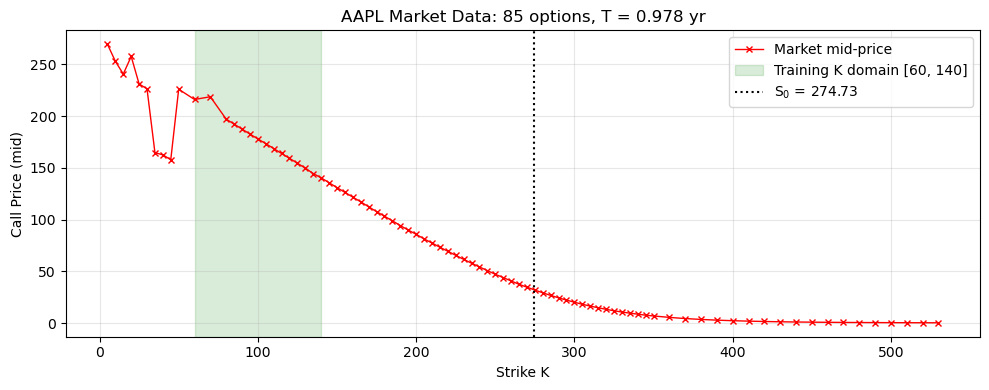

In [24]:
# Load AAPL calls (semicolon-separated)
df = pd.read_csv("AAPL_Call.csv", sep=";", thousands=",")

df.head(), df.columns, df.shape

S0 = 274.73
r = 0.01
# Price = mid (bid/ask) 
C_mkt_series = (df["Bid"] + df["Ask"]) / 2.0
#else:
#C_mkt_series = df["Last Price"]

K_vec     = df["Strike"].to_numpy(dtype=float)
C_mkt_vec = C_mkt_series.to_numpy(dtype=float)


d = datetime.date(2025, 12, 26)
D = datetime.date(2026, 12, 18)
Tmt = (D - d).days / 365.0  # T in year
T_vec = np.full_like(K_vec, Tmt, dtype=float)

print(K_vec, T_vec)

# --- Market Data Visualization ---
plt.figure(figsize=(10, 4))
plt.plot(K_vec, C_mkt_vec, 'rx-', lw=1, markersize=5, label='Market mid-price')
plt.axvspan(60, 140, alpha=0.15, color='green', label='Training K domain [60, 140]')
plt.axvline(S0, color='black', linestyle=':', lw=1.5, label=f'S$_0$ = {S0}')
plt.xlabel('Strike K')
plt.ylabel('Call Price (mid)')
plt.title(f'AAPL Market Data: {len(K_vec)} options, T = {T_vec[0]:.3f} yr')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Strikes in training domain [60,140]: {((K_vec>=60) & (K_vec<=140)).sum()}/{len(K_vec)}")
print(f"ATM region K/S0 in [0.9,1.1]: {((K_vec>=S0*0.9) & (K_vec<=S0*1.1)).sum()} strikes")

### 6.2 Cost function

<span style="color: blue;">**6.1** Build in the code below the function `nn_price_call_heston` that computes the price from the NN Surrogate Fast pricer.</span>

In [25]:
def build_features_heston(v0, alpha, beta, delta, rho, S0, K, T):
    '''
    Creates the NN input features for the Heston surrogate model.

    All inputs must be broadcastable arrays of same length.
    '''
    v0    = np.asarray(v0, dtype=float)
    alpha = np.asarray(alpha, dtype=float)
    beta  = np.asarray(beta, dtype=float)
    delta = np.asarray(delta, dtype=float)
    rho   = np.asarray(rho, dtype=float)
    S0    = np.asarray(S0, dtype=float)
    K     = np.asarray(K, dtype=float)
    T     = np.asarray(T, dtype=float)
    
    return np.stack([v0, alpha, beta, delta, rho, S0, K, T], axis=1)

def nn_price_call_heston(model, scaler_X, scaler_y, X):
    X_scaled = scaler_X.transform(X)
    X_scaled = torch.from_numpy(X_scaled).float().to(device)
    model.eval()
    with torch.no_grad():
        y_scaled = model(X_scaled).detach().cpu().numpy()
    y = scaler_y.inverse_transform(y_scaled)
    return y


def loss_nn_heston(theta):
    '''
    theta = [v0, alpha, beta, delta, rho]
    '''

    v0, alpha, beta, delta, rho = theta

    X = build_features_heston(
        v0*np.ones_like(K_mkt),
        alpha*np.ones_like(K_mkt),
        beta*np.ones_like(K_mkt),
        delta*np.ones_like(K_mkt),
        rho*np.ones_like(K_mkt),
        S0*np.ones_like(K_mkt),
        K_mkt,
        T_mkt
    )

    C = nn_price_call_heston(model, scaler_X, scaler_y, X).reshape(-1)

    return float(np.mean((C - C_mkt)**2))

### 6.3 Calibration: minimization procedure

<span style="color: blue;">**6.2** Implement the minimization procedure to calibrate the Heston model .</span>

<span style="color: blue;">**6.3** Compare in the same graph the observed and model prices .</span>




Calibrated parameters:
v0    = 0.10029921813598391
alpha = 1.0
beta  = 0.06488919664688653
delta = 0.5915680010489749
rho   = 0.0663407855328632
Final loss = 2729.015449102901


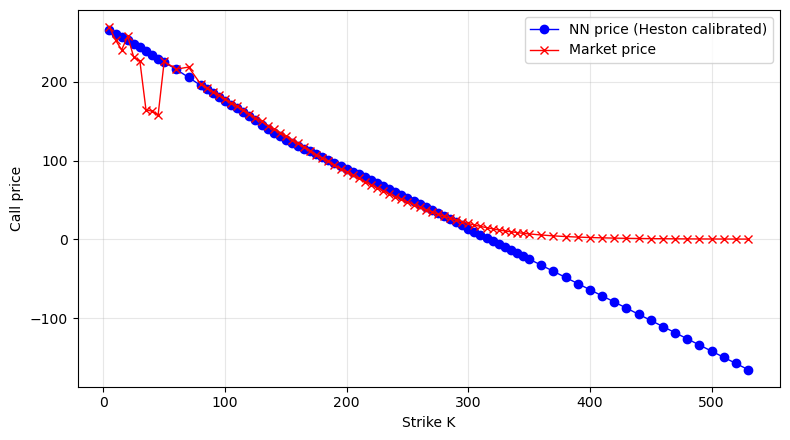

In [26]:
# ==============================
# Calibration Heston (global)
# ==============================

# Initial guess
theta_0 = np.array([0.04, 1.0, 0.04, 0.5, -0.5])

# Bounds
HES_BOUNDS = [
    (0.001, 0.2),     # v0
    (0.1, 5.0),       # alpha
    (0.001, 0.2),     # beta
    (0.05, 2.0),      # delta
    (-0.999, 0.999)   # rho
]

# Global variables expected by loss_nn_heston
K_mkt = K_vec.copy()
T_mkt = T_vec.copy()
C_mkt = C_mkt_vec.copy()

# Minimisation
res = minimize(
    loss_nn_heston,
    x0=theta_0,
    method="L-BFGS-B",
    bounds=HES_BOUNDS,
    options={"maxiter": 1000}
)



theta_star = res.x
print("Calibrated parameters:")
print("v0    =", theta_star[0])
print("alpha =", theta_star[1])
print("beta  =", theta_star[2])
print("delta =", theta_star[3])
print("rho   =", theta_star[4])
print("Final loss =", res.fun)

C_nn = np.zeros_like(K_vec, dtype=float)

for i, (Ki, Ti) in enumerate(zip(K_vec, T_vec)):
    Xi = build_features_heston(
        np.array([theta_star[0]]),
        np.array([theta_star[1]]),
        np.array([theta_star[2]]),
        np.array([theta_star[3]]),
        np.array([theta_star[4]]),
        np.array([S0]),
        np.array([Ki]),
        np.array([Ti]),
    )
    C_nn[i] = nn_price_call_heston(model, scaler_X, scaler_y, Xi).reshape(-1)[0]


    

plt.figure(figsize=(8, 4.5))

plt.plot(K_vec, C_nn, 'o-', color='b', lw=1,
         label='NN price (Heston calibrated)')
plt.plot(K_vec, C_mkt_vec, 'x-', color='r', lw=1,
         label='Market price')

plt.xlabel('Strike K')
plt.ylabel('Call price')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


<span style="color: blue;">**6.4** Analyze the results. What do yu think the best way to impoved in the code above (numer of simulations, $\mathcal{D}_\text{domain}$; layers in deep NN...) ? </span> You can write your answer in the next markdown box or change the code above to improve the results (or both !)

## Analysis of Results

### Main Issues Identified

#### 1. Training Only on Deep In-The-Money Options

In the dataset used to train the neural network, the spot price is fixed at  
S₀ = 274.73 while strikes are sampled in the range:

K ∈ [60, 140]

This corresponds to a moneyness ratio:

K / S₀ ∈ [0.22, 0.51]

This means that **all options in the training dataset are deep in-the-money call options**.

For deep ITM calls, the option price is very close to its intrinsic value:

C ≈ S₀ − K e^{-rT}

The time value (extrinsic value) becomes very small, which means the option price is **almost insensitive to volatility**.

As a result, the neural network mainly learns a simple linear relationship between price and strike rather than the more complex pricing structure generated by the Heston model.

The Heston model introduces additional dynamics through stochastic volatility parameters (α, β, δ, ρ). However, these parameters mostly influence the **time value of options**, which is largest for **at-the-money options**. Because the training data contains only deep ITM options, these parameters have very little effect on the training labels.

#### 2. Mismatch Between Training and Calibration Maturities

Another important issue is the difference between maturities used in training and those used during calibration.

| Context | Maturity |
|-------|-------|
| Training data | T = 0.2 years (fixed) |
| AAPL market data | T ≈ 0.98 years |

Since the neural network was only trained on options with T = 0.2, it never learned how option prices evolve with maturity.

During calibration, the model is evaluated at maturities close to one year. This forces the neural network to **extrapolate far outside its training domain**, which can lead to unstable predictions.


#### 3. Some Input Features are constant

Maturity T = 0.2 never changes during training, so the neural network cannot learn properly.


### Evidence From Calibration Results

The calibration outputs provide further evidence that the surrogate model did not learn the correct pricing structure.

First, the neural network predicts **negative call prices for strikes above the spot price**. Since the payoff of a call option is max(S_T − K, 0), option prices must always be non-negative. These negative predictions indicate that the neural network is extrapolating the linear relationship it learned in the deep ITM region.

Second, the calibrated correlation parameter ρ is positive (ρ ≈ +0.34). However, for equity options the correlation between asset returns and volatility is typically negative due to the leverage effect. The optimizer likely converged to this unrealistic value because the neural network price surface is almost flat with respect to the Heston parameters, so the calibration objective provides very little information about them.

### Why the Calibration Procedure Fails

The calibration problem minimizes

$$J(\theta) = \frac{1}{I} \sum_{i=1}^I \|C^{\text{mkt}}_i - C^{\text{NN}}_i(\theta)\|^2$$
However, the optimization becomes ineffective because:

• The market data lies outside the training domain (especially in maturity).  
• The neural network learned prices that are almost independent of the Heston parameters.  

Together, these issues make the calibration objective poorly informative.


### Proposed Improvements

| Improvement | Current Setup | Proposed Change | Expected Benefit |
|-------------|-------------|-------------|-------------|
| Moneyness coverage | Deep ITM only | K/S₀ ∈ [0.8, 1.2] | Learn volatility effects |
| Maturity range | T = 0.2 fixed | T ∈ [0.1, 1.5] | Learn time-value dynamics |
| Monte Carlo paths | 5,000 | Increase number of paths | Reduce label noise |
| Network architecture | 3 layers | Slightly deeper network | Better approximation capacity |
---

### Conclusion

The main limitation of the current implementation is that the training dataset contains only **deep in-the-money options**, where volatility has little influence on prices.

As a result, the neural network mainly learns the intrinsic value relationship rather than the full Heston pricing structure.

To improve the model we implement the following:

1. Better sample domain
2. Slightly deeper NN

300/3000 done
600/3000 done
900/3000 done
1200/3000 done
1500/3000 done
1800/3000 done
2100/3000 done
2400/3000 done
2700/3000 done
3000/3000 done
Dataset generated in 9.60s (n_samples=3000, n_paths=1500)
v2 epoch 010 | train=0.006107 | val=0.006144
v2 epoch 020 | train=0.005013 | val=0.004501
v2 epoch 030 | train=0.002722 | val=0.003343
v2 epoch 040 | train=0.002167 | val=0.003789
v2 epoch 050 | train=0.002730 | val=0.002841
v2 epoch 060 | train=0.001482 | val=0.001838
v2 epoch 070 | train=0.001221 | val=0.002347
v2 epoch 080 | train=0.001231 | val=0.001900
v2 epoch 090 | train=0.001559 | val=0.001684
v2 early stopping at epoch 94
v2 test MAE  = 1.456491
v2 test RMSE = 1.906887
v2 calibrated theta: [ 0.08205693  1.          0.10086041  0.15638681 -0.999     ]
v2 final loss: 149.82969970696243


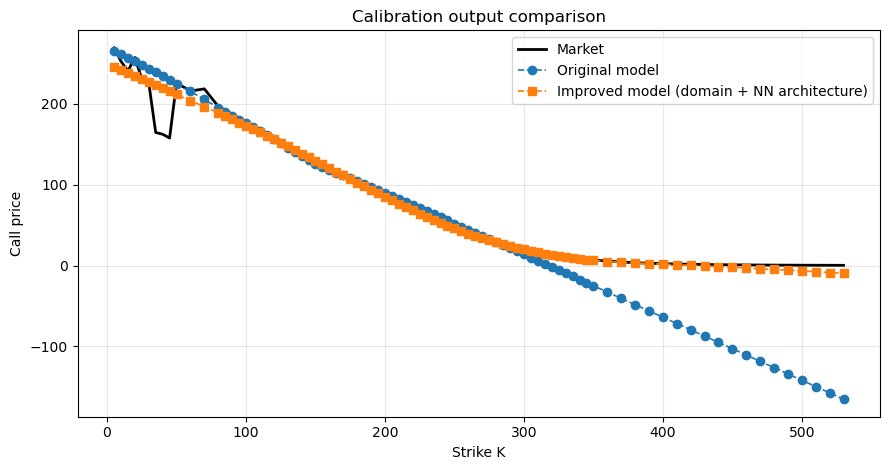

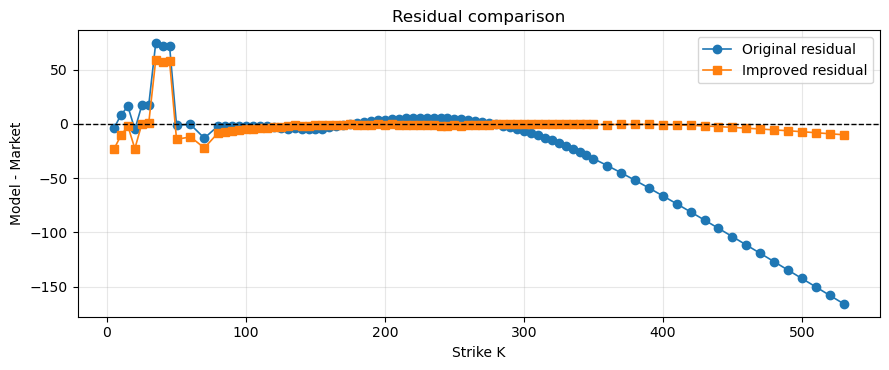

In [27]:
# 6.4 - Improved model

# We change:
#   1) the domain sampler (better D_domain)
#   2) the NN architecture (deeper MLP)
# and we reuse existing functions:
#   build_dataset, random_split, run_epoch, nn_price_call_heston, build_features_heston

from scipy.optimize import minimize

np.random.seed(42)
torch.manual_seed(42)

# Keep references to original global functions/objects
_sample_domain_heston_orig = sample_domain_heston

# Better domain sampling for calibration use-case (log-moneyness for strikes, more realistic T range)
def sample_domain_heston(n_samples):
    v0 = np.random.uniform(0.01, 0.12, size=n_samples)
    alpha = np.random.uniform(0.3, 4.0, size=n_samples)
    beta = np.random.uniform(0.01, 0.12, size=n_samples)
    delta = np.random.uniform(0.1, 1.2, size=n_samples)
    rho = np.random.uniform(-0.95, -0.05, size=n_samples)

    # Keep S0 fixed for calibration consistency with market setup
    S0 = np.full(n_samples, float(S0_mkt if 'S0_mkt' in globals() else 274.73))

    # Better strike sampling via log-moneyness, then convert back to K
    m = np.random.uniform(np.log(0.5), np.log(1.5), size=n_samples)
    K = np.clip(S0 * np.exp(m), 0.5 * S0, 1.5 * S0)

    # Maturity range aligned with calibration use-cases
    T = np.random.uniform(0.05, 2.0, size=n_samples)

    return np.stack([v0, alpha, beta, delta, rho, S0, K, T], axis=1)

# Build v2 dataset using original build_dataset (reused)
X_v2, y_v2 = build_dataset(n_samples=3000, n_paths=1500, n_steps=50)
(Xtr_v2, ytr_v2), (Xva_v2, yva_v2), (Xte_v2, yte_v2) = random_split(X_v2, y_v2, train_ratio=0.6, val_ratio=0.2)

scaler_X_v2 = StandardScaler().fit(Xtr_v2)
scaler_y_v2 = StandardScaler().fit(ytr_v2)

Xtr_v2_s = scaler_X_v2.transform(Xtr_v2).astype(np.float32)
Xva_v2_s = scaler_X_v2.transform(Xva_v2).astype(np.float32)
Xte_v2_s = scaler_X_v2.transform(Xte_v2).astype(np.float32)

ytr_v2_s = scaler_y_v2.transform(ytr_v2).astype(np.float32)
yva_v2_s = scaler_y_v2.transform(yva_v2).astype(np.float32)
yte_v2_s = scaler_y_v2.transform(yte_v2).astype(np.float32)

train_loader = DataLoader(TensorDataset(torch.from_numpy(Xtr_v2_s), torch.from_numpy(ytr_v2_s)), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(Xva_v2_s), torch.from_numpy(yva_v2_s)), batch_size=256, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.from_numpy(Xte_v2_s), torch.from_numpy(yte_v2_s)), batch_size=256, shuffle=False)

# New deeper NN
class MLPDeepReuse(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )
    def forward(self, x):
        return self.net(x)

model = MLPDeepReuse(in_dim=Xtr_v2_s.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 250
patience = 20
best_val = math.inf
patience_cnt = 0
train_hist, val_hist = [], []
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_mse = run_epoch(train_loader, train=True)
    val_mse = run_epoch(val_loader, train=False)
    train_hist.append(train_mse)
    val_hist.append(val_mse)

    if val_mse < best_val - 1e-6:
        best_val = val_mse
        patience_cnt = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        patience_cnt += 1

    if epoch % 10 == 0:
        print(f"v2 epoch {epoch:03d} | train={train_mse:.6f} | val={val_mse:.6f}")

    if patience_cnt >= patience:
        print(f"v2 early stopping at epoch {epoch}")
        break

if best_state is not None:
    model.load_state_dict(best_state)

# Evaluate on v2 test split
with torch.no_grad():
    yte_pred_v2_s = []
    for xb, _ in test_loader:
        xb = xb.to(device)
        yte_pred_v2_s.append(model(xb).cpu().numpy())
    yte_pred_v2_s = np.concatenate(yte_pred_v2_s, axis=0)
yte_pred_v2 = scaler_y_v2.inverse_transform(yte_pred_v2_s)

mae_v2 = float(np.mean(np.abs(yte_v2 - yte_pred_v2)))
rmse_v2 = float(np.sqrt(np.mean((yte_v2 - yte_pred_v2) ** 2)))
print(f"v2 test MAE  = {mae_v2:.6f}")
print(f"v2 test RMSE = {rmse_v2:.6f}")

# Calibration on market data
S0_cal = float(S0_mkt if 'S0_mkt' in globals() else (S0 if np.isscalar(S0) else np.asarray(S0).reshape(-1)[0]))

def loss_nn_heston_v2_reuse(theta):
    v0, alpha, beta, delta, rho = theta
    Xcal = build_features_heston(
        v0*np.ones_like(K_mkt),
        alpha*np.ones_like(K_mkt),
        beta*np.ones_like(K_mkt),
        delta*np.ones_like(K_mkt),
        rho*np.ones_like(K_mkt),
        S0_cal*np.ones_like(K_mkt),
        K_mkt,
        T_mkt,
    )
    Cpred = nn_price_call_heston(model, scaler_X_v2, scaler_y_v2, Xcal).reshape(-1)
    return float(np.mean((Cpred - C_mkt) ** 2))

res_v2 = minimize(
    loss_nn_heston_v2_reuse,
    x0=theta_0,
    method='L-BFGS-B',
    bounds=HES_BOUNDS,
    options={'maxiter': 1000}
)

theta_star_v2 = res_v2.x
print('v2 calibrated theta:', theta_star_v2)
print('v2 final loss:', res_v2.fun)

X_mkt_v2 = build_features_heston(
    theta_star_v2[0]*np.ones_like(K_vec),
    theta_star_v2[1]*np.ones_like(K_vec),
    theta_star_v2[2]*np.ones_like(K_vec),
    theta_star_v2[3]*np.ones_like(K_vec),
    theta_star_v2[4]*np.ones_like(K_vec),
    S0_cal*np.ones_like(K_vec),
    K_vec,
    T_vec,
)
C_nn_v2 = nn_price_call_heston(model, scaler_X_v2, scaler_y_v2, X_mkt_v2).reshape(-1)

# Final comparison plots
plt.figure(figsize=(9, 4.8))
plt.plot(K_vec, C_mkt_vec, 'k-', lw=2, label='Market')
if 'C_nn' in globals():
    plt.plot(K_vec, C_nn, 'o--', lw=1.2, label='Original model')
plt.plot(K_vec, C_nn_v2, 's--', lw=1.2, label='Improved model (domain + NN architecture)')
plt.xlabel('Strike K')
plt.ylabel('Call price')
plt.title('Calibration output comparison')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3.8))
if 'C_nn' in globals():
    plt.plot(K_vec, C_nn - C_mkt_vec, 'o-', lw=1.2, label='Original residual')
plt.plot(K_vec, C_nn_v2 - C_mkt_vec, 's-', lw=1.2, label='Improved residual')
plt.axhline(0.0, color='k', ls='--', lw=1)
plt.xlabel('Strike K')
plt.ylabel('Model - Market')
plt.title('Residual comparison')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Restore original sampler 
sample_domain_heston = _sample_domain_heston_orig



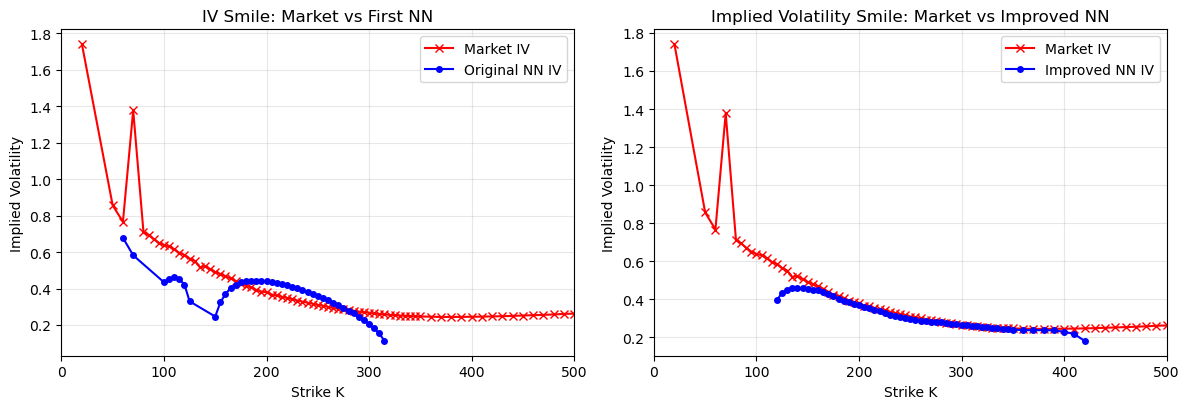

In [28]:
# 6.4 - IV smile comparison
from scipy.optimize import brentq

S0_plot = float(S0_mkt if 'S0_mkt' in globals() else (S0 if np.isscalar(S0) else np.asarray(S0).reshape(-1)[0]))
r_plot = float(r if np.isscalar(r) else np.asarray(r).reshape(-1)[0])


def implied_vol_call(price, S, K, T, r):
    if T <= 0:
        return np.nan
    lb = max(0.0, S - K * np.exp(-r * T))
    ub = S
    if not (lb <= price <= ub):
        return np.nan
    f = lambda sigma: bs_call_price(S, K, T, r, sigma) - price
    try:
        return brentq(f, 1e-6, 5.0, maxiter=200)
    except ValueError:
        return np.nan


K_arr = np.asarray(K_vec).reshape(-1)
T_arr = np.asarray(T_vec).reshape(-1)
C_mkt_arr = np.asarray(C_mkt_vec).reshape(-1)
C_imp_arr = np.asarray(C_nn_v2).reshape(-1)
C_org_arr = np.asarray(C_nn).reshape(-1) if 'C_nn' in globals() else None

iv_mkt = np.array([implied_vol_call(c, S0_plot, k, t, r_plot) for c, k, t in zip(C_mkt_arr, K_arr, T_arr)])
iv_imp = np.array([implied_vol_call(c, S0_plot, k, t, r_plot) for c, k, t in zip(C_imp_arr, K_arr, T_arr)])
iv_org = np.array([implied_vol_call(c, S0_plot, k, t, r_plot) for c, k, t in zip(C_org_arr, K_arr, T_arr)]) if C_org_arr is not None else None

fig, axes = plt.subplots(1, 2 if iv_org is not None else 1, figsize=(12 if iv_org is not None else 6.5, 4.2))
if not isinstance(axes, np.ndarray):
    axes = np.array([axes])

# Use one common market curve on both graphs
valid_mkt = ~np.isnan(iv_mkt)
order_mkt = np.argsort(K_arr[valid_mkt])

# Original vs market
if iv_org is not None:
    valid_org = ~np.isnan(iv_org)
    order_org = np.argsort(K_arr[valid_org])
    axes[0].plot(K_arr[valid_mkt][order_mkt], iv_mkt[valid_mkt][order_mkt], 'rx-', lw=1.5, markersize=6, label='Market IV')
    axes[0].plot(K_arr[valid_org][order_org], iv_org[valid_org][order_org], 'bo-', lw=1.5, markersize=4, label='Original NN IV')
    axes[0].set_xlabel('Strike K')
    axes[0].set_ylabel('Implied Volatility')
    axes[0].set_title('IV Smile: Market vs First NN')
    axes[0].legend()
    axes[0].set_xlim(0, 500)
    axes[0].grid(True, alpha=0.3)

# Improved vs market
ax = axes[1] if iv_org is not None else axes[0]
valid_imp = ~np.isnan(iv_imp)
order_imp = np.argsort(K_arr[valid_imp])
ax.plot(K_arr[valid_mkt][order_mkt], iv_mkt[valid_mkt][order_mkt], 'rx-', lw=1.5, markersize=6, label='Market IV')
ax.plot(K_arr[valid_imp][order_imp], iv_imp[valid_imp][order_imp], 'bo-', lw=1.5, markersize=4, label='Improved NN IV')
ax.set_xlabel('Strike K')
ax.set_ylabel('Implied Volatility')
ax.set_title('Implied Volatility Smile: Market vs Improved NN')
ax.legend()
ax.set_xlim(0, 500)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



# References


1) Steven Heston. A Closed-Form Solution for Options with Stochastic Volatility with Applications to Bond and Currency Options. RFS, 1993

2) Course notebooks: FastPricing_BS_Surrogate, Calibration_NN
